# 10 · Helping the Rare Classes

**The question:** Every model so far does worst on the smallest classes (Worms, Shellcode, Backdoor, Analysis, DoS). If we make mistakes on rare
classes **cost more** during training, do we detect them better, and what does it cost elsewhere?

| | |
|---|---|
| **Input** | The `total_and_byte44` inputs (Notebook 05): tree version for LightGBM, scaled version for the network |
| **What we do** | Compare four ways to treat rare classes (none, softer weights, balanced weights, SMOTE) on LightGBM **and** the network, with matched rules |
| **Output** | The best rare-class treatment for each model family, which Notebooks 11-15 then use |

**Fairness rule:** whatever helps the network is also offered to LightGBM. A weighted network is never compared with only an unweighted LightGBM.

## 1. Setup

In [1]:
import sys
import time
import warnings
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())))
warnings.filterwarnings('ignore')

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from lightgbm import LGBMClassifier
from scipy import sparse
from sklearn.metrics import confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import NearestNeighbors

from src.notebook_helpers import (ROOT, TRAIN_CSV, RAW_SHA256, CLASSES, DATA, MODELS,
                                  sha256, save_table, save_figure, save_json, read_json, setup_style, write_leaderboard)
from src.flow_networks import (FlowData, BASE_CONFIG, run_config, class_weights, score, paired_comparison,
                               bootstrap_difference, leaderboard_row, DEVICE, show_code)
setup_style()
assert sha256(TRAIN_CSV) == RAW_SHA256['train']
RARE = ['Worms', 'Shellcode', 'Backdoor', 'Analysis', 'DoS']
print('network device:', DEVICE)

network device: cuda


## 2. How rare are the rare classes?

The weights below are what each treatment gives a mistake on one row of that class (a Normal mistake is the reference).

- **Balanced:** weight = 1 / (share of the class). A Worms row then counts as much as about 430 Normal rows.
- **Softer (square root):** the square root of the balanced weight. Rare classes still count more, but much less extremely.

In [2]:
X = {(v, r): sparse.load_npz(DATA / f'05_total_and_byte44_{v}_{r}.npz') for v in ['tree'] for r in ['train', 'model_selection']}
targets = {r: pd.read_csv(DATA / f'03_targets_{r}.csv') for r in ['train', 'model_selection']}
y_train = pd.Categorical(targets['train'].attack_cat, categories=CLASSES).codes.astype(np.int64)
y_eval = pd.Categorical(targets['model_selection'].attack_cat, categories=CLASSES).codes.astype(np.int64)

counts = pd.Series(np.bincount(y_train, minlength=10), index=CLASSES)
weights = pd.DataFrame({'train rows': counts,
                        'sqrt weight': class_weights(y_train, 'sqrt'), 'balanced weight': class_weights(y_train, 'balanced')})
weights['sqrt (relative to Normal)'] = weights['sqrt weight'] / weights.loc['Normal', 'sqrt weight']
weights['balanced (relative to Normal)'] = weights['balanced weight'] / weights.loc['Normal', 'balanced weight']
save_table(weights, '10_class_weights', index=True)
display(weights.sort_values('train rows')[['train rows', 'sqrt (relative to Normal)', 'balanced (relative to Normal)']])

,train rows,sqrt (relative to Normal),balanced (relative to Normal)
Worms,104,20.7550,430.7692
Shellcode,907,7.0281,49.3936
Backdoor,1397,5.6629,32.0687
Analysis,1600,5.2915,28.0000
Reconnaissance,8393,2.3104,5.3378
DoS,9811,2.1369,4.5663
Fuzzers,14547,1.7549,3.0797
Exploits,26714,1.2950,1.6770
Generic,32000,1.1832,1.4000
Normal,44800,1.0000,1.0000


## 3. SMOTE: making new rare-class rows

**SMOTE** (Synthetic Minority Over-sampling) creates new rows for a rare class: take a real row, pick one of its 5 nearest neighbours **of the same class**,
and place a new row at a random point on the line between them. The reference paper used SMOTE.

Our version, written out in full:

- Only classes with fewer than **5,000** train rows are filled up to 5,000: Worms, Shellcode, Backdoor and Analysis.
- Distances are measured on `sign(x)·log(1 + |x|)` of the number columns, so huge values do not dominate.
- New number values are interpolated on the original scale; the text columns (one-hot) are copied from the starting row, because "half tcp, half udp" makes no sense.
- SMOTE is applied **only to the rows used for training** at that moment, never to rows used for checking.

In [3]:
names = read_json(MODELS / '05_feature_sets.json')['columns']['total_and_byte44/tree']
number_cols = np.array([i for i, n in enumerate(names) if not n.startswith('cat__')])
TARGET_ROWS = 5000


def smote(x, y, target=TARGET_ROWS, k=5, seed=42):
    """Return x, y with synthetic rows added for every class below `target` rows."""
    rng = np.random.default_rng(seed)
    x = sparse.csr_matrix(x)
    new_x, new_y = [], []
    for cls in range(10):
        rows = np.flatnonzero(y == cls)
        need = target - len(rows)
        if need <= 0 or len(rows) < 2:
            continue
        dense = x[rows].toarray()
        space = np.sign(dense[:, number_cols]) * np.log1p(np.abs(dense[:, number_cols]))
        neighbours = NearestNeighbors(n_neighbors=min(k + 1, len(rows))).fit(space).kneighbors(space, return_distance=False)[:, 1:]
        start = rng.integers(0, len(rows), need)
        partner = neighbours[start, rng.integers(0, neighbours.shape[1], need)]
        gap = rng.random((need, 1))
        synthetic = dense[start].copy()                                        # text one-hot columns copied from the start row
        synthetic[:, number_cols] = dense[start][:, number_cols] + gap * (dense[partner][:, number_cols] - dense[start][:, number_cols])
        new_x.append(sparse.csr_matrix(synthetic)); new_y.append(np.full(need, cls))
    return sparse.vstack([x] + new_x, format='csr'), np.concatenate([y] + new_y)


demo_x, demo_y = smote(X[('tree', 'train')], y_train)
display(pd.DataFrame({'before': np.bincount(y_train, minlength=10), 'after SMOTE': np.bincount(demo_y, minlength=10)}, index=CLASSES).T)

,Analysis,Backdoor,DoS,Exploits,Fuzzers,Generic,Normal,Reconnaissance,Shellcode,Worms
before,1600,1397,9811,26714,14547,32000,44800,8393,907,104
after SMOTE,5000,5000,9811,26714,14547,32000,44800,8393,5000,5000


## 4. LightGBM: choose the treatment inside the train rows

We must not pick the treatment by looking at `model_selection`. So we split the **train rows** into 3 parts, keeping identical patterns together
(as in Notebook 02), train on two parts and check on the third, three times. The treatment with the highest average macro F1 wins.

(The one-hot vocabulary of the inputs was learned on all train rows in Notebook 03. Inside these folds that only means a category can exist
as a column without appearing in a fold; it does not leak any label information.)

In [4]:
def make_lgbm():
    return LGBMClassifier(objective='multiclass', n_estimators=120, learning_rate=0.1, num_leaves=31, reg_lambda=1.0,
                          min_child_samples=20, random_state=42, n_jobs=8, deterministic=True, force_col_wise=True, verbosity=-1)


def fit_lgbm(x, y, treatment):
    if treatment == 'smote':
        x, y = smote(x, y)
        return make_lgbm().fit(x, y)
    w = class_weights(y, treatment)
    return make_lgbm().fit(x, y, sample_weight=w[y])


TREATMENTS = ['none', 'sqrt', 'balanced', 'smote']
roles = pd.read_csv(DATA / '02_roles.csv')
patterns = roles.loc[roles.role == 'train', 'pattern'].to_numpy()
inner = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42).split(np.zeros(len(y_train)), y_train, patterns))

inner_rows = []
for treatment in TREATMENTS:
    for fold, (fit_rows, check_rows) in enumerate(inner, start=1):
        start = time.time()
        model = fit_lgbm(X[('tree', 'train')][fit_rows], y_train[fit_rows], treatment)
        pred = model.predict(X[('tree', 'train')][check_rows])
        inner_rows.append({'treatment': treatment, 'fold': fold,
                           'macro F1': f1_score(y_train[check_rows], pred, average='macro', labels=range(10), zero_division=0)})
        print(f'LightGBM {treatment:8s} inner fold {fold}: macro F1 {inner_rows[-1]["macro F1"]:.4f} ({time.time() - start:.0f} s)')
inner_scores = pd.DataFrame(inner_rows)
inner_summary = inner_scores.groupby('treatment', sort=False)['macro F1'].agg(['mean', 'std']).rename(columns=lambda c: f'inner macro F1 {c}')
save_table(inner_summary, '10_lgbm_inner_folds', index=True)
display(inner_summary)
LGBM_CHOICE = inner_summary['inner macro F1 mean'].idxmax()
print('LightGBM treatment chosen inside the train rows:', LGBM_CHOICE)

LightGBM none     inner fold 1: macro F1 0.5990 (5 s)


LightGBM none     inner fold 2: macro F1 0.5921 (5 s)


LightGBM none     inner fold 3: macro F1 0.5984 (5 s)


LightGBM sqrt     inner fold 1: macro F1 0.6389 (5 s)


LightGBM sqrt     inner fold 2: macro F1 0.6508 (5 s)


LightGBM sqrt     inner fold 3: macro F1 0.6496 (5 s)


... (4 outputs left out)

LightGBM smote    inner fold 2: macro F1 0.6011 (6 s)


LightGBM smote    inner fold 3: macro F1 0.6122 (6 s)


,inner macro F1 mean,inner macro F1 std
treatment,,
none,0.5965,0.0038
sqrt,0.6464,0.0066
balanced,0.6159,0.0034
smote,0.6028,0.0087


LightGBM treatment chosen inside the train rows: sqrt


## 5. LightGBM: train every treatment on all train rows

We train all four on the full train rows, so we can also *see* the effect of each one on `model_selection`. Only the chosen one goes forward.

In [5]:
lgbm_proba, lgbm_rows = {}, []
for treatment in TREATMENTS:
    model = fit_lgbm(X[('tree', 'train')], y_train, treatment)
    lgbm_proba[treatment] = model.predict_proba(X[('tree', 'model_selection')])
    joblib.dump(model, MODELS / f'10_lightgbm_{treatment}.joblib')
    lgbm_rows.append({'treatment': treatment, **score(y_eval, lgbm_proba[treatment])})
lgbm_results = pd.DataFrame(lgbm_rows).set_index('treatment')
save_table(lgbm_results, '10_lgbm_results', index=True)
display(lgbm_results)

,macro F1,accuracy,attack recall,false-positive rate,attack avg precision,Worms correct (of 13)
treatment,,,,,,
none,0.6320,0.8356,0.9753,0.0845,0.9967,9
sqrt,0.6662,0.8176,0.9883,0.1202,0.9966,11
balanced,0.6308,0.7801,0.9947,0.1589,0.9964,11
smote,0.6215,0.8327,0.9760,0.0909,0.9967,8


**What we see:**

- **Softer (sqrt) weights are the best treatment for LightGBM:** macro F1 **0.666** instead of 0.632, and 11 of 13 Worms rows found instead of 9.
  The inner folds (train rows only) ranked the treatments in the same order, so the choice did not depend on `model_selection`.
- The price is **more false alarms**: the false-positive rate rises from 8.5% to 12.0%, while attack recall rises from 97.5% to 98.8%.
- **Balanced weights go too far:** the same macro F1 as no treatment (0.631) but 15.9% false alarms.
- **SMOTE, the reference paper's method, does not help** (0.621, slightly below no treatment).

## 6. The network: the same idea with loss weights

The network is the Notebook 08 design with one change that later notebooks need: the three text columns (protocol, service, state) now join the
attention as **tokens**, like the number features, instead of being added only at the end. Training now runs on the **GPU**, with the Notebook 08 rules
(early stopping on a grouped 10% of the train rows, at most 100 epochs).

SMOTE is not used for the network: its interpolated rows would need their own neighbour rules for the token embeddings, and weighting already gives the
network the same signal. We compare **none, softer and balanced** weights, 3 seeds each, and choose by the macro F1 on the **stopping rows**
(which are train rows, so `model_selection` is not used for the choice).

In [6]:
data = FlowData('total_and_byte44')
net_runs, net_proba = {}, {}
for treatment in ['none', 'sqrt', 'balanced']:
    runs, proba, _, _ = run_config(data, dict(BASE_CONFIG, weighting=treatment), label=f'network {treatment}')
    net_runs[treatment], net_proba[treatment] = runs, proba

net_summary = pd.DataFrame({t: {'stopping macro F1 (mean)': r['stopping macro F1'].mean(),
                                'model_selection macro F1 (mean)': r['macro F1'].mean(),
                                'model_selection macro F1 (std)': r['macro F1'].std(),
                                'false-positive rate (mean)': r['false-positive rate'].mean(),
                                'Worms correct (mean of 13)': r['Worms correct (of 13)'].mean()} for t, r in net_runs.items()}).T
save_table(net_summary, '10_network_results', index=True)
display(net_summary)
NET_CHOICE = net_summary['stopping macro F1 (mean)'].idxmax()
print('Network weighting chosen on the stopping rows:', NET_CHOICE)

network none seed 42: model_selection macro F1 0.5144 | stopping macro F1 0.5157
network none seed 43: model_selection macro F1 0.5132 | stopping macro F1 0.5333


network none seed 44: model_selection macro F1 0.5120 | stopping macro F1 0.5271
network sqrt seed 42: model_selection macro F1 0.6043 | stopping macro F1 0.6018


network sqrt seed 43: model_selection macro F1 0.5787 | stopping macro F1 0.5854
network sqrt seed 44: model_selection macro F1 0.5794 | stopping macro F1 0.5913


network balanced seed 42: model_selection macro F1 0.5244 | stopping macro F1 0.5238
network balanced seed 43: model_selection macro F1 0.4892 | stopping macro F1 0.4903


network balanced seed 44: model_selection macro F1 0.4986 | stopping macro F1 0.5015


,stopping macro F1 (mean),model_selection macro F1 (mean),model_selection macro F1 (std),false-positive rate (mean),Worms correct (mean of 13)
none,0.5254,0.5132,0.0012,0.1163,0.0000
sqrt,0.5928,0.5875,0.0146,0.1852,7.3333
balanced,0.5052,0.5041,0.0182,0.2068,10.6667


Network weighting chosen on the stopping rows: sqrt


**What we see:**

- The network reacts the same way: **sqrt weights raise its macro F1 from 0.513 to 0.587** (3-seed means), and Worms goes from 0 to about 7 of 13.
- Balanced weights do not help the network either (0.504).
- The cost is again more false alarms: 11.6% → 18.5% of Normal flows are flagged.

## 7. Is the improvement real?

Bootstrap intervals (as in Notebook 06) for the chosen treatment against no treatment. For the network we compare seed with seed.

In [7]:
rows = []
if LGBM_CHOICE != 'none':
    d, lo, hi, v = bootstrap_difference(y_eval, lgbm_proba[LGBM_CHOICE].argmax(1), lgbm_proba['none'].argmax(1))
    rows.append({'comparison': f'LightGBM {LGBM_CHOICE} vs none', 'seed': '-', 'difference': d, '95% low': lo, '95% high': hi, 'verdict': v})
for treatment in ['sqrt', 'balanced']:
    frame, overall = paired_comparison(y_eval, net_proba[treatment], net_proba['none'], f'network {treatment} vs none')
    rows += frame.to_dict('records')
significance = pd.DataFrame(rows)
save_table(significance, '10_significance')
display(significance)

,comparison,seed,difference,95% low,95% high,verdict
0,LightGBM sqrt vs none,-,0.0343,0.0168,0.0547,first clearly better
1,network sqrt vs none,42,0.0899,0.0686,0.1111,first clearly better
2,network sqrt vs none,43,0.0656,0.0469,0.0838,first clearly better
3,network sqrt vs none,44,0.0674,0.0485,0.0863,first clearly better
4,network balanced vs none,42,0.0100,-0.0030,0.0238,could be chance
5,network balanced vs none,43,-0.0240,-0.0362,-0.0110,second clearly better
6,network balanced vs none,44,-0.0134,-0.0262,0.0002,could be chance


## 8. What happens to each class?

Recall (share of a class that is found) and precision (share of alarms for a class that are right), before and after the chosen treatment.
For the network we use seed 42.

LightGBM none               LightGBM sqrt               network none               network sqrt              
              precision recall     F1     precision recall     F1    precision recall     F1    precision recall     F1
Worms            0.7500 0.6920 0.7200        0.6470 0.8460 0.7330       0.0000 0.0000 0.0000       0.2500 0.6150 0.3560
Shellcode        0.7150 0.7790 0.7460        0.6330 0.9290 0.7530       0.6640 0.6460 0.6550       0.4820 0.8410 0.6130
Backdoor         0.5420 0.1490 0.2330        0.4230 0.1890 0.2610       0.7860 0.0630 0.1160       0.4430 0.1770 0.2530
Analysis         0.5660 0.1500 0.2370        0.3480 0.1600 0.2190       0.6000 0.0750 0.1330       0.2940 0.2250 0.2550
DoS              0.6670 0.0700 0.1270        0.3580 0.7720 0.4890       0.5830 0.0290 0.0540       0.3430 0.7700 0.4750
Exploits         0.6220 0.9560 0.7540        0.8170 0.6060 0.6960       0.6100 0.9440 0.7410       0.8220 0.5510 0.6600
Normal           0.9460 0.9160 0.9300        0.9720 0.8800 0.9240       0.9400 0.8860 0.9120       0.9820 0.8300 0.9000

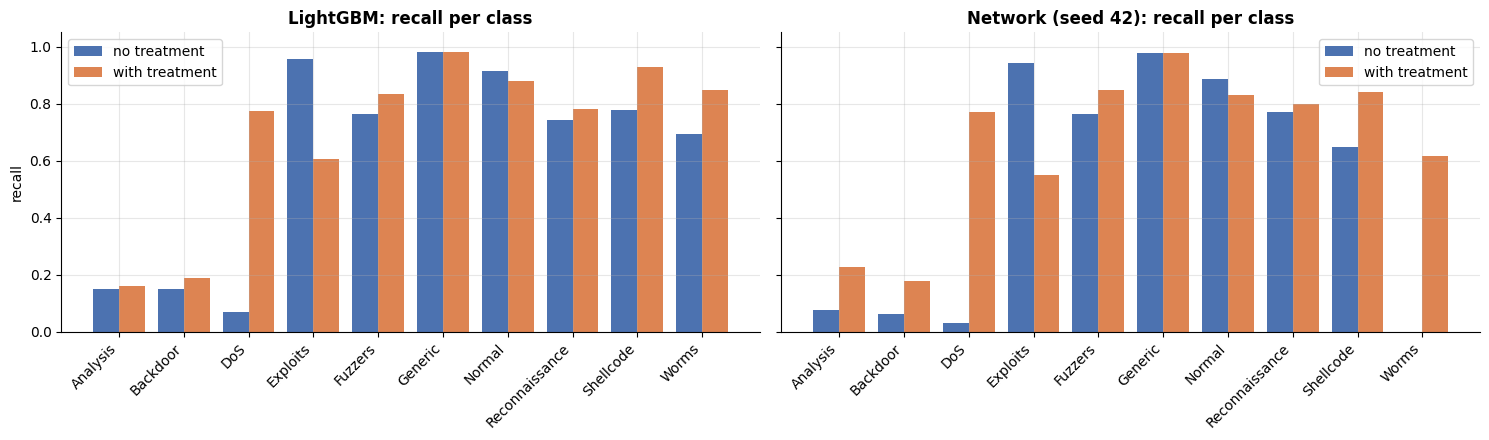

In [8]:
def class_table(proba):
    p, r, f, _ = precision_recall_fscore_support(y_eval, proba.argmax(1), labels=range(10), zero_division=0)
    return pd.DataFrame({'precision': p, 'recall': r, 'F1': f}, index=CLASSES)


compare = pd.concat({'LightGBM none': class_table(lgbm_proba['none']), f'LightGBM {LGBM_CHOICE}': class_table(lgbm_proba[LGBM_CHOICE]),
                     'network none': class_table(net_proba['none'][42]), f'network {NET_CHOICE}': class_table(net_proba[NET_CHOICE][42])}, axis=1)
save_table(compare, '10_per_class', index=True)
display(compare.loc[RARE + ['Exploits', 'Normal']].round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, (family, before, after) in zip(axes, [('LightGBM', lgbm_proba['none'], lgbm_proba[LGBM_CHOICE]),
                                              ('Network (seed 42)', net_proba['none'][42], net_proba[NET_CHOICE][42])]):
    rb = class_table(before)['recall']; ra = class_table(after)['recall']
    x = np.arange(10)
    ax.bar(x - 0.2, rb, 0.4, label='no treatment', color='#4C72B0'); ax.bar(x + 0.2, ra, 0.4, label='with treatment', color='#DD8452')
    ax.set_xticks(x, CLASSES, rotation=45, ha='right'); ax.set(title=f'{family}: recall per class', ylim=(0, 1.05)); ax.legend()
axes[0].set_ylabel('recall')
plt.tight_layout(); save_figure(fig, '10_recall_per_class'); plt.show()

**What we see:**

- **The big winner is DoS:** LightGBM's DoS recall jumps from 0.07 to **0.77** (F1 0.13 → 0.49); the network shows the same jump (0.03 → 0.77).
  Worms and Shellcode recall also rise.
- **The cost falls on Exploits and Normal:** Exploits recall drops from 0.96 to 0.61, and Normal recall from 0.92 to 0.88.
- **Analysis and Backdoor barely improve** (F1 about 0.22-0.26). Their rows share identical measurements with other classes (Notebook 02), so
  weighting cannot pull them apart.

## 9. Where do the errors move?

Analysis, Backdoor and DoS share identical measurements with Exploits (Notebook 02). Weighting cannot separate identical rows; it can only change
**which label** the model gives them. Here is where the rows of these three classes end up, without and with balanced weighting (network, seed 42).

In [9]:
def where_they_go(proba):
    cm = confusion_matrix(y_eval, proba.argmax(1), labels=range(10))
    return pd.DataFrame(cm, index=CLASSES, columns=CLASSES).loc[['Analysis', 'Backdoor', 'DoS'], ['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Normal']]


display(pd.concat({'network, no weighting': where_they_go(net_proba['none'][42]),
                   'network, balanced weighting': where_they_go(net_proba['balanced'][42])}, axis=1))
moved = (confusion_matrix(y_eval, net_proba['balanced'][42].argmax(1), labels=range(10))[:, CLASSES.index('Exploits')]
         - confusion_matrix(y_eval, net_proba['none'][42].argmax(1), labels=range(10))[:, CLASSES.index('Exploits')])
print('Change in rows predicted as Exploits, per true class:', dict(zip(CLASSES, moved.tolist())))

network, no weighting                              network, balanced weighting                              
                      Analysis Backdoor DoS Exploits Normal                    Analysis Backdoor  DoS Exploits Normal
Analysis                    15        0   1      155     29                          54       58   87        1      0
Backdoor                     0       11   3      158      3                           0       90   77        1      0
DoS                          0        2  35     1135      9                          16      429  576      133      0

Change in rows predicted as Exploits, per true class: {'Analysis': -154, 'Backdoor': -157, 'DoS': -1002, 'Exploits': -1727, 'Fuzzers': -165, 'Generic': -39, 'Normal': -31, 'Reconnaissance': -234, 'Shellcode': -12, 'Worms': -10}


**What we see:**

- Without weighting, almost all Analysis, Backdoor and DoS rows are predicted as **Exploits** (155, 158 and 1,135 rows).
- With balanced weighting they **leave Exploits**, but mostly move to each other: 429 DoS rows become Backdoor, 87 Analysis rows become DoS.
- In total 1,727 fewer true Exploits rows are predicted as Exploits. **The errors move; they do not disappear.** This is the label-conflict ceiling
  from Notebook 02 in action: identical measurements cannot be split by any weighting.

## 10. Decision and save

**Rule (fixed in advance):** each family keeps the treatment chosen *inside the train rows* (inner folds for LightGBM, stopping rows for the network).
Notebooks 11-15 train every network with the network's chosen weighting, and compare against LightGBM with its chosen treatment.

In [10]:
choice = {'lightgbm_treatment': LGBM_CHOICE, 'network_weighting': NET_CHOICE,
          'rule': 'chosen inside the train rows (LightGBM: 3 grouped inner folds; network: grouped stopping rows), never on model_selection'}
save_json(choice, MODELS / '10_rare_class_choice.json')
display(pd.Series(choice).to_frame('decision'))

board = [{'model': f'LightGBM ({t})' if t != 'none' else 'LightGBM', 'feature set': 'total_and_byte44', 'runs': 1,
          'macro F1 mean': lgbm_results.loc[t, 'macro F1'], 'macro F1 std': np.nan, 'accuracy': lgbm_results.loc[t, 'accuracy'],
          'attack recall': lgbm_results.loc[t, 'attack recall'], 'false-positive rate': lgbm_results.loc[t, 'false-positive rate'],
          'attack avg precision': lgbm_results.loc[t, 'attack avg precision'], 'Worms correct (of 13)': lgbm_results.loc[t, 'Worms correct (of 13)']}
         for t in TREATMENTS if t != 'none']
board += [leaderboard_row(f'FlowNet base, GPU ({t} weighting)', r) for t, r in net_runs.items()]
write_leaderboard('10', board)
for t, proba in net_proba.items():
    for seed, p in proba.items():
        pd.DataFrame(p, columns=[f'p_{c}' for c in CLASSES]).to_csv(DATA / f'10_network_{t}_seed{seed}_proba.csv', index=False)
for t, p in lgbm_proba.items():
    pd.DataFrame(p, columns=[f'p_{c}' for c in CLASSES]).to_csv(DATA / f'10_lightgbm_{t}_proba.csv', index=False)
assert sha256(TRAIN_CSV) == RAW_SHA256['train']
print('Saved the choice, models, probabilities and leaderboard rows. Calibration rows and the test file were not used.')

,decision
lightgbm_treatment,sqrt
network_weighting,sqrt
rule,chosen inside the train rows (LightGBM: 3 grou...


Saved the choice, models, probabilities and leaderboard rows. Calibration rows and the test file were not used.


## Summary

### What we learned

| Question | Answer |
|---|---|
| Best treatment for LightGBM | **sqrt class weights**: macro F1 0.632 → **0.666**, clearly better (bootstrap interval above 0); chosen inside the train rows |
| Best treatment for the network | **sqrt class weights**: 0.513 → **0.587**, clearly better for all 3 seeds |
| Balanced weights / SMOTE | Not helpful: no gain, many more false alarms (balanced), or a small loss (SMOTE) |
| Where the gain comes from | Mostly **DoS** (recall 0.07 → 0.77), plus Worms and Shellcode |
| The cost | More false alarms (LightGBM 8.5% → 12.0%) and lower Exploits recall (0.96 → 0.61) |
| The limit | Analysis and Backdoor stay hard: their errors move between conflicting classes instead of disappearing |

### Decision

Both families use **sqrt weights** from now on. Notebooks 11-15 train every network with them, and LightGBM (sqrt) is the comparison bar:
macro F1 **0.666** on `model_selection`.

### What is still uncertain

- The false-alarm cost may matter more than macro F1 in some deployments; Notebook 17's abstention rule and Notebook 19's test results show it again.
- With 13 Worms rows, the Worms gains are still a matter of a few rows.

### What comes next

**Notebook 11** tests the first architecture block of the proposed network: a multi-scale convolution.